<div style="background: linear-gradient(135deg, #0a0e1a 0%, #0f1729 50%, #1a0a2e 100%); padding: 60px 40px; border-radius: 16px; border: 1px solid #1e3a5f; text-align: center; margin-bottom: 10px;">

<h1 style="font-size: 3.2em; font-weight: 900; background: linear-gradient(90deg, #7eb8f7, #a78bfa, #67e8c0); -webkit-background-clip: text; -webkit-text-fill-color: transparent; margin: 0 0 10px 0; letter-spacing: -1px;">
The Art of Chaos
</h1>

<p style="font-size: 0.9em; color: #3a5f8a; letter-spacing: 5px; text-transform: uppercase; margin: 0 0 20px 0; font-family: monospace;">
A Visual Journey Through Dynamical Systems & Fractals
</p>

<p style="font-size: 1.1em; color: #7a95b8; max-width: 700px; margin: 0 auto 30px auto; line-height: 1.8;">
Somewhere between order and randomness lives a universe of infinite complexity —
generated by equations so simple, a child could write them.
</p>

<div style="display: flex; justify-content: center; gap: 12px; flex-wrap: wrap;">
<span style="background: #0d1f35; border: 1px solid #1e3a5f; color: #7eb8f7; padding: 6px 16px; border-radius: 20px; font-size: 0.8em; font-family: monospace;">LORENZ</span>
<span style="background: #1a0d35; border: 1px solid #3a1f6a; color: #a78bfa; padding: 6px 16px; border-radius: 20px; font-size: 0.8em; font-family: monospace;">MANDELBROT</span>
<span style="background: #0d2a25; border: 1px solid #1a4a3a; color: #67e8c0; padding: 6px 16px; border-radius: 20px; font-size: 0.8em; font-family: monospace;">JULIA SETS</span>
<span style="background: #2a1f0d; border: 1px solid #4a3a1a; color: #f7c873; padding: 6px 16px; border-radius: 20px; font-size: 0.8em; font-family: monospace;">BIFURCATION</span>
<span style="background: #2a0d1f; border: 1px solid #4a1a35; color: #f472b6; padding: 6px 16px; border-radius: 20px; font-size: 0.8em; font-family: monospace;">LYAPUNOV</span>
</div>

</div>

## Contents

| # | Section | Topic |
|:---:|:---|:---|
| 01 | The Butterfly Effect | Lorenz attractor from 80,000 points |
| 02 | Strange Attractor Gallery | Six systems with different geometry |
| 03 | The Road to Chaos | Bifurcation diagram and Feigenbaum's constant |
| 04 | The Mandelbrot Set | One rule, detail at every scale |

Part 2 continues with sections 5 to 8: Julia sets, Lyapunov exponents, the animated Lorenz attractor, and Poincare sections.

[Continue to Part 2](the-art-of-chaos-part2.ipynb)


---
## ⚙️ Setup & Configuration

In [1]:
# ╔══════════════════════════════════════════════════════════╗
# ║           IMPORTS & GLOBAL AESTHETIC CONFIG              ║
# ╚══════════════════════════════════════════════════════════╝

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.animation import FuncAnimation, PillowWriter
from mpl_toolkits.mplot3d import Axes3D
from scipy.integrate import solve_ivp
import warnings
warnings.filterwarnings('ignore')

# ── Aesthetic dark palette ──────────────────────────────────
PALETTE = {
    'bg':      '#080b14',
    'surface': '#0d1117',
    'border':  '#1e2d45',
    'text':    '#8fa3c0',
    'blue':    '#7eb8f7',
    'purple':  '#a78bfa',
    'cyan':    '#67e8c0',
    'gold':    '#f7c873',
    'rose':    '#f472b6',
    'dim':     '#2a3f5f',
}

CMAPS = {
    'chaos':  LinearSegmentedColormap.from_list('chaos',
        ['#080b14','#0f2040','#1a0533','#4c1d95','#7eb8f7','#67e8c0','#f7c873'], N=512),
    'lorenz': LinearSegmentedColormap.from_list('lorenz',
        ['#080b14','#0c2461','#1e3799','#4a69bd','#7eb8f7','#a8d8f0','#ffffff'], N=512),
    'mandel': LinearSegmentedColormap.from_list('mandel',
        ['#080b14','#1a0533','#4c1d95','#a78bfa','#f7c873','#f472b6','#ffffff'], N=1024),
    'fire':   LinearSegmentedColormap.from_list('fire',
        ['#080b14','#3d0000','#c0392b','#e74c3c','#f39c12','#f7c873','#ffffff'], N=512),
    'bifur':  LinearSegmentedColormap.from_list('bifur',
        ['#080b14','#0d2137','#67e8c0','#a78bfa'], N=256),
}

plt.rcParams.update({
    'figure.facecolor':  PALETTE['bg'],
    'axes.facecolor':    PALETTE['surface'],
    'axes.edgecolor':    PALETTE['border'],
    'axes.labelcolor':   PALETTE['text'],
    'xtick.color':       PALETTE['dim'],
    'ytick.color':       PALETTE['dim'],
    'text.color':        PALETTE['text'],
    'grid.color':        PALETTE['border'],
    'grid.alpha':        0.4,
    'font.family':       'monospace',
    'figure.dpi':        130,
    'savefig.facecolor': PALETTE['bg'],
    'savefig.bbox':      'tight',
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

print("\u2746  Environment ready. Let the chaos begin.")

❆  Environment ready. Let the chaos begin.


---

<div style="background: linear-gradient(90deg, #0d1f35, #0a0e1a); padding: 20px 28px; border-radius: 10px; border-left: 4px solid #7eb8f7; margin: 20px 0;">
<p style="color: #3a5f8a; font-family: monospace; font-size: 0.8em; letter-spacing: 3px; margin: 0 0 4px 0;">§ 01 · THE BUTTERFLY EFFECT</p>
<h2 style="color: #7eb8f7; margin: 0; font-size: 1.8em;">🦋 The Lorenz Attractor</h2>
</div>

In **1963**, meteorologist Edward Lorenz was running weather simulations when he discovered something that would change science forever. He re-ran a simulation with what he thought was the same starting point — but had rounded `0.506127` to `0.506`. The results were **completely different.**

The three equations below define the Lorenz system — they look innocent:

$$rac{dx}{dt} = \sigma(y - x)$$

$$rac{dy}{dt} = x(ho - z) - y$$

$$rac{dz}{dt} = xy - eta z$$

With **σ=10, ρ=28, β=8/3**, these equations never repeat, never settle — they trace an eternal butterfly through phase space.

> ⚡ **KEY INSIGHT**
>
> The Lorenz system is **deterministic** — the same initial conditions always produce the same trajectory.
> Yet it is **unpredictable**, because we can never measure initial conditions with infinite precision.
> This is not a measurement problem. It is a **fundamental feature of the universe.**

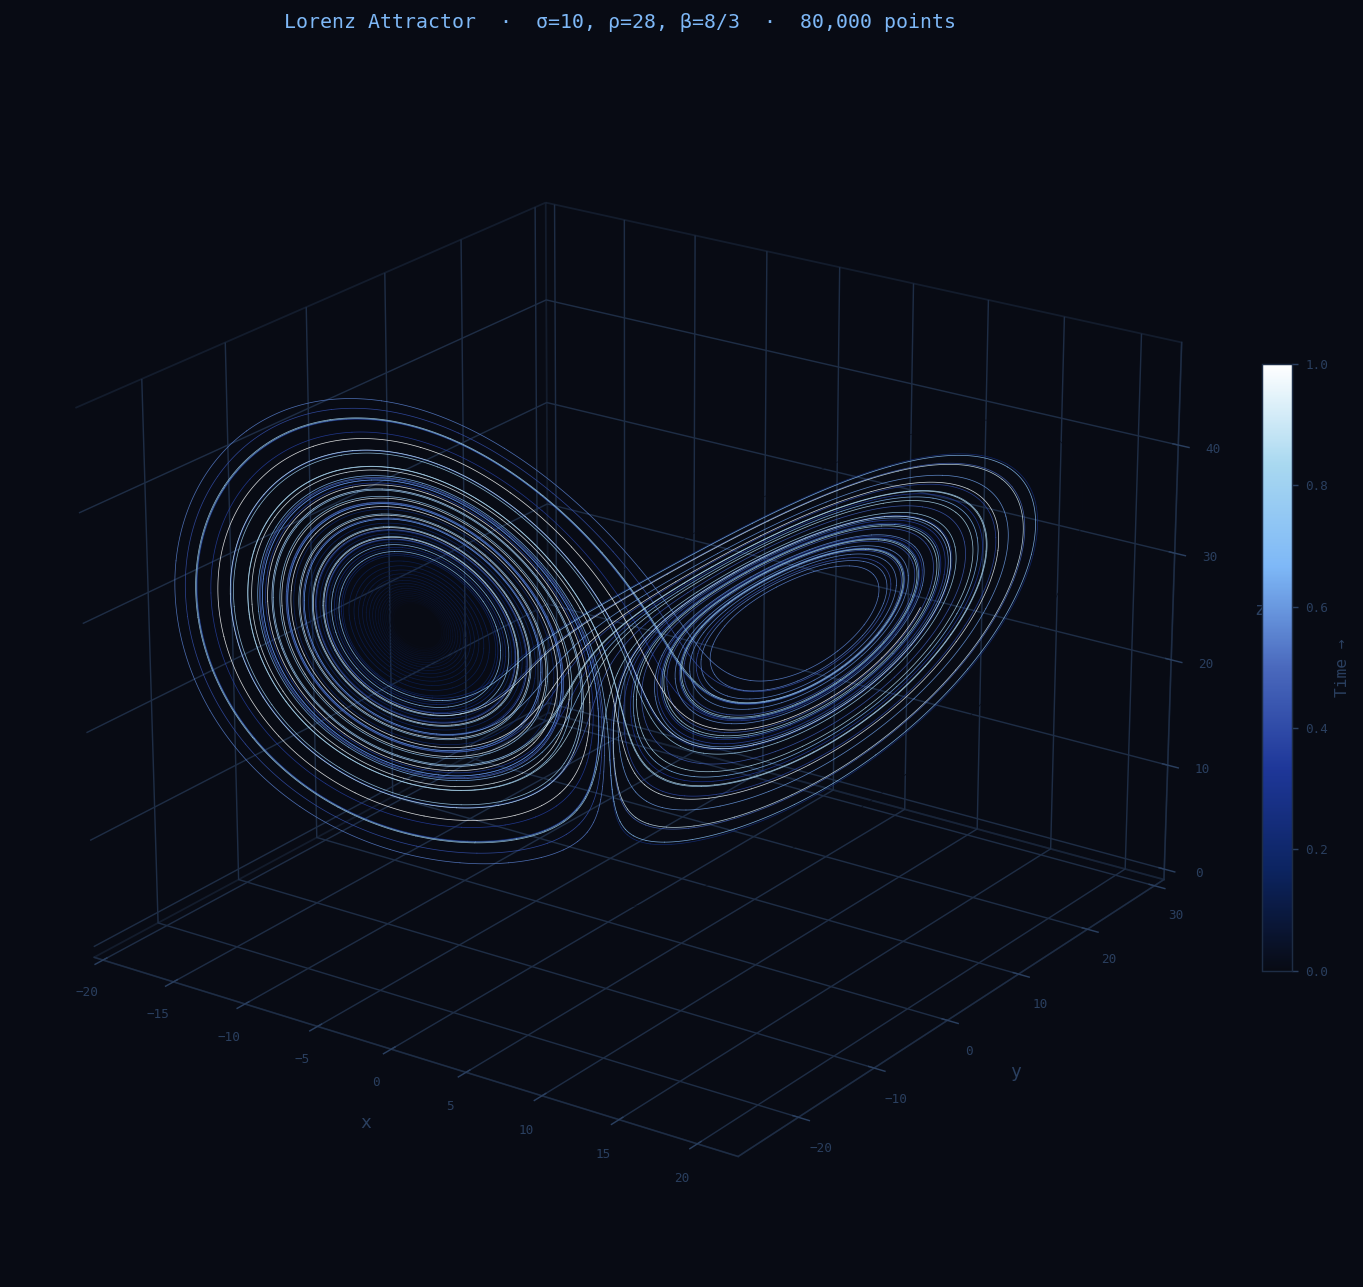

❆  80,000 steps of pure deterministic chaos rendered.


In [2]:
# ══════════════════════════════════════════════
#  LORENZ ATTRACTOR — High-res 3D Phase Portrait
# ══════════════════════════════════════════════

def lorenz(t, state, sigma=10.0, rho=28.0, beta=8/3):
    x, y, z = state
    return [sigma*(y - x), x*(rho - z) - y, x*y - beta*z]

t_span = (0, 80)
t_eval = np.linspace(*t_span, 80_000)
sol = solve_ivp(lorenz, t_span, [0.1, 0., 0.], t_eval=t_eval,
                method='RK45', rtol=1e-9, atol=1e-11)
x, y, z = sol.y

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')
ax.set_facecolor(PALETTE['bg'])
fig.patch.set_facecolor(PALETTE['bg'])

norm = Normalize(vmin=0, vmax=1)
cmap = CMAPS['lorenz']
n_seg = 2000
seg_len = len(x) // n_seg
for i in range(n_seg):
    s, e = i*seg_len, (i+1)*seg_len
    ax.plot(x[s:e+1], y[s:e+1], z[s:e+1],
            color=cmap(norm(i/n_seg)), linewidth=0.4, alpha=0.85)

ax.set_xlabel('x', labelpad=8, fontsize=10, color=PALETTE['dim'])
ax.set_ylabel('y', labelpad=8, fontsize=10, color=PALETTE['dim'])
ax.set_zlabel('z', labelpad=8, fontsize=10, color=PALETTE['dim'])
ax.xaxis.pane.fill = False; ax.yaxis.pane.fill = False; ax.zaxis.pane.fill = False
ax.xaxis.pane.set_edgecolor(PALETTE['border'])
ax.yaxis.pane.set_edgecolor(PALETTE['border'])
ax.zaxis.pane.set_edgecolor(PALETTE['border'])
ax.tick_params(colors=PALETTE['dim'], labelsize=7)
ax.view_init(elev=22, azim=-55)
ax.grid(True, alpha=0.15, color=PALETTE['border'])
ax.set_title('Lorenz Attractor  \u00b7  \u03c3=10, \u03c1=28, \u03b2=8/3  \u00b7  80,000 points',
             fontsize=11, color=PALETTE['blue'], pad=18, fontfamily='monospace')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.02)
cbar.ax.tick_params(colors=PALETTE['dim'], labelsize=7)
cbar.set_label('Time \u2192', color=PALETTE['dim'], fontsize=9)
plt.tight_layout()
plt.show()
print("\u2746  80,000 steps of pure deterministic chaos rendered.")

### The Butterfly Effect — Visualized

Two trajectories starting **0.0000001 apart.** Watch what happens over time:

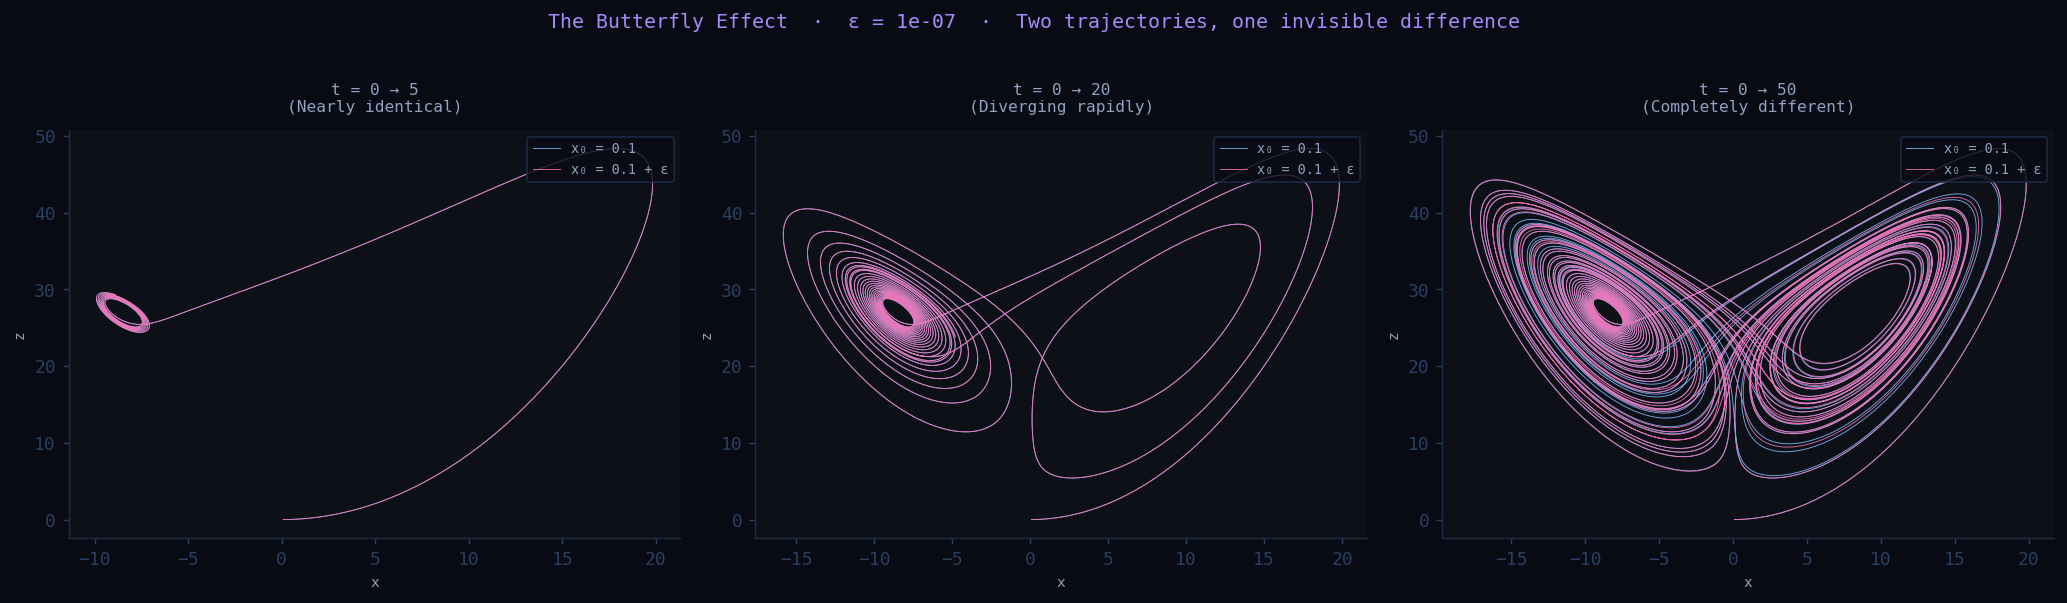

❆  A difference of 1e-07 creates a completely different universe.


In [3]:
# ══════════════════════════════════════════════
#  BUTTERFLY EFFECT — Two nearly identical trajectories
# ══════════════════════════════════════════════

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig.patch.set_facecolor(PALETTE['bg'])

epsilon = 1e-7
for ax, t_end, title in zip(axes,
    [5, 20, 50],
    ['t = 0 \u2192 5\n(Nearly identical)', 't = 0 \u2192 20\n(Diverging rapidly)', 't = 0 \u2192 50\n(Completely different)']):

    t_eval_b = np.linspace(0, t_end, 30_000)
    sol1 = solve_ivp(lorenz, (0, t_end), [0.1, 0., 0.], t_eval=t_eval_b, rtol=1e-10, atol=1e-12)
    sol2 = solve_ivp(lorenz, (0, t_end), [0.1+epsilon, 0., 0.], t_eval=t_eval_b, rtol=1e-10, atol=1e-12)

    ax.set_facecolor(PALETTE['surface'])
    ax.plot(sol1.y[0], sol1.y[2], linewidth=0.5, alpha=0.9, color=PALETTE['blue'], label='x\u2080 = 0.1')
    ax.plot(sol2.y[0], sol2.y[2], linewidth=0.5, alpha=0.9, color=PALETTE['rose'], label='x\u2080 = 0.1 + \u03b5')
    ax.set_title(title, fontsize=9, color=PALETTE['text'], fontfamily='monospace', pad=10)
    ax.legend(fontsize=7.5, loc='upper right',
              facecolor=PALETTE['bg'], edgecolor=PALETTE['border'], labelcolor=PALETTE['text'])
    ax.set_xlabel('x', fontsize=8); ax.set_ylabel('z', fontsize=8)
    for spine in ax.spines.values(): spine.set_edgecolor(PALETTE['border'])

fig.suptitle(f'The Butterfly Effect  \u00b7  \u03b5 = {epsilon:.0e}  \u00b7  Two trajectories, one invisible difference',
             fontsize=11, color=PALETTE['purple'], fontfamily='monospace', y=1.02)
plt.tight_layout()
plt.show()
print(f"\u2746  A difference of {epsilon} creates a completely different universe.")

---

<div style="background: linear-gradient(90deg, #1a0d35, #0a0e1a); padding: 20px 28px; border-radius: 10px; border-left: 4px solid #a78bfa; margin: 20px 0;">
<p style="color: #4a2a8a; font-family: monospace; font-size: 0.8em; letter-spacing: 3px; margin: 0 0 4px 0;">§ 02 · A MENAGERIE OF STRANGE ATTRACTORS</p>
<h2 style="color: #a78bfa; margin: 0; font-size: 1.8em;">🌀 Strange Attractor Gallery</h2>
</div>

The Lorenz system is just the beginning. Mathematicians have discovered an entire **zoo of strange attractors** — each with its own personality, geometry, and brand of infinite complexity.

What makes an attractor *strange*? It lives on a **fractal** — a geometric object with **non-integer dimension**. The Lorenz attractor has fractal dimension ≈ **2.06**. More than a surface, less than a volume.

> 📐 **FRACTAL DIMENSION**
>
> Classical geometry: 1D lines, 2D surfaces, 3D volumes.
> Fractal geometry shatters this. The Lorenz attractor lives in **2.06 dimensions** — 
> it fills space like a crumpled surface that never quite becomes a solid.
> This is where chaos lives.

| Attractor | Discoverer | Character |
|:---|:---|:---|
| **Lorenz** | Edward Lorenz, 1963 | The original butterfly — weather chaos |
| **Rössler** | Otto Rössler, 1976 | Spiral chaos — simpler than Lorenz |
| **Halvorsen** | — | Three-fold symmetry, wild spirals |
| **Aizawa** | — | Toroidal structure, alien geometry |
| **Dadras** | — | Complex folding behavior |
| **Thomas** | René Thomas | Labyrinthine — cubic symmetry |

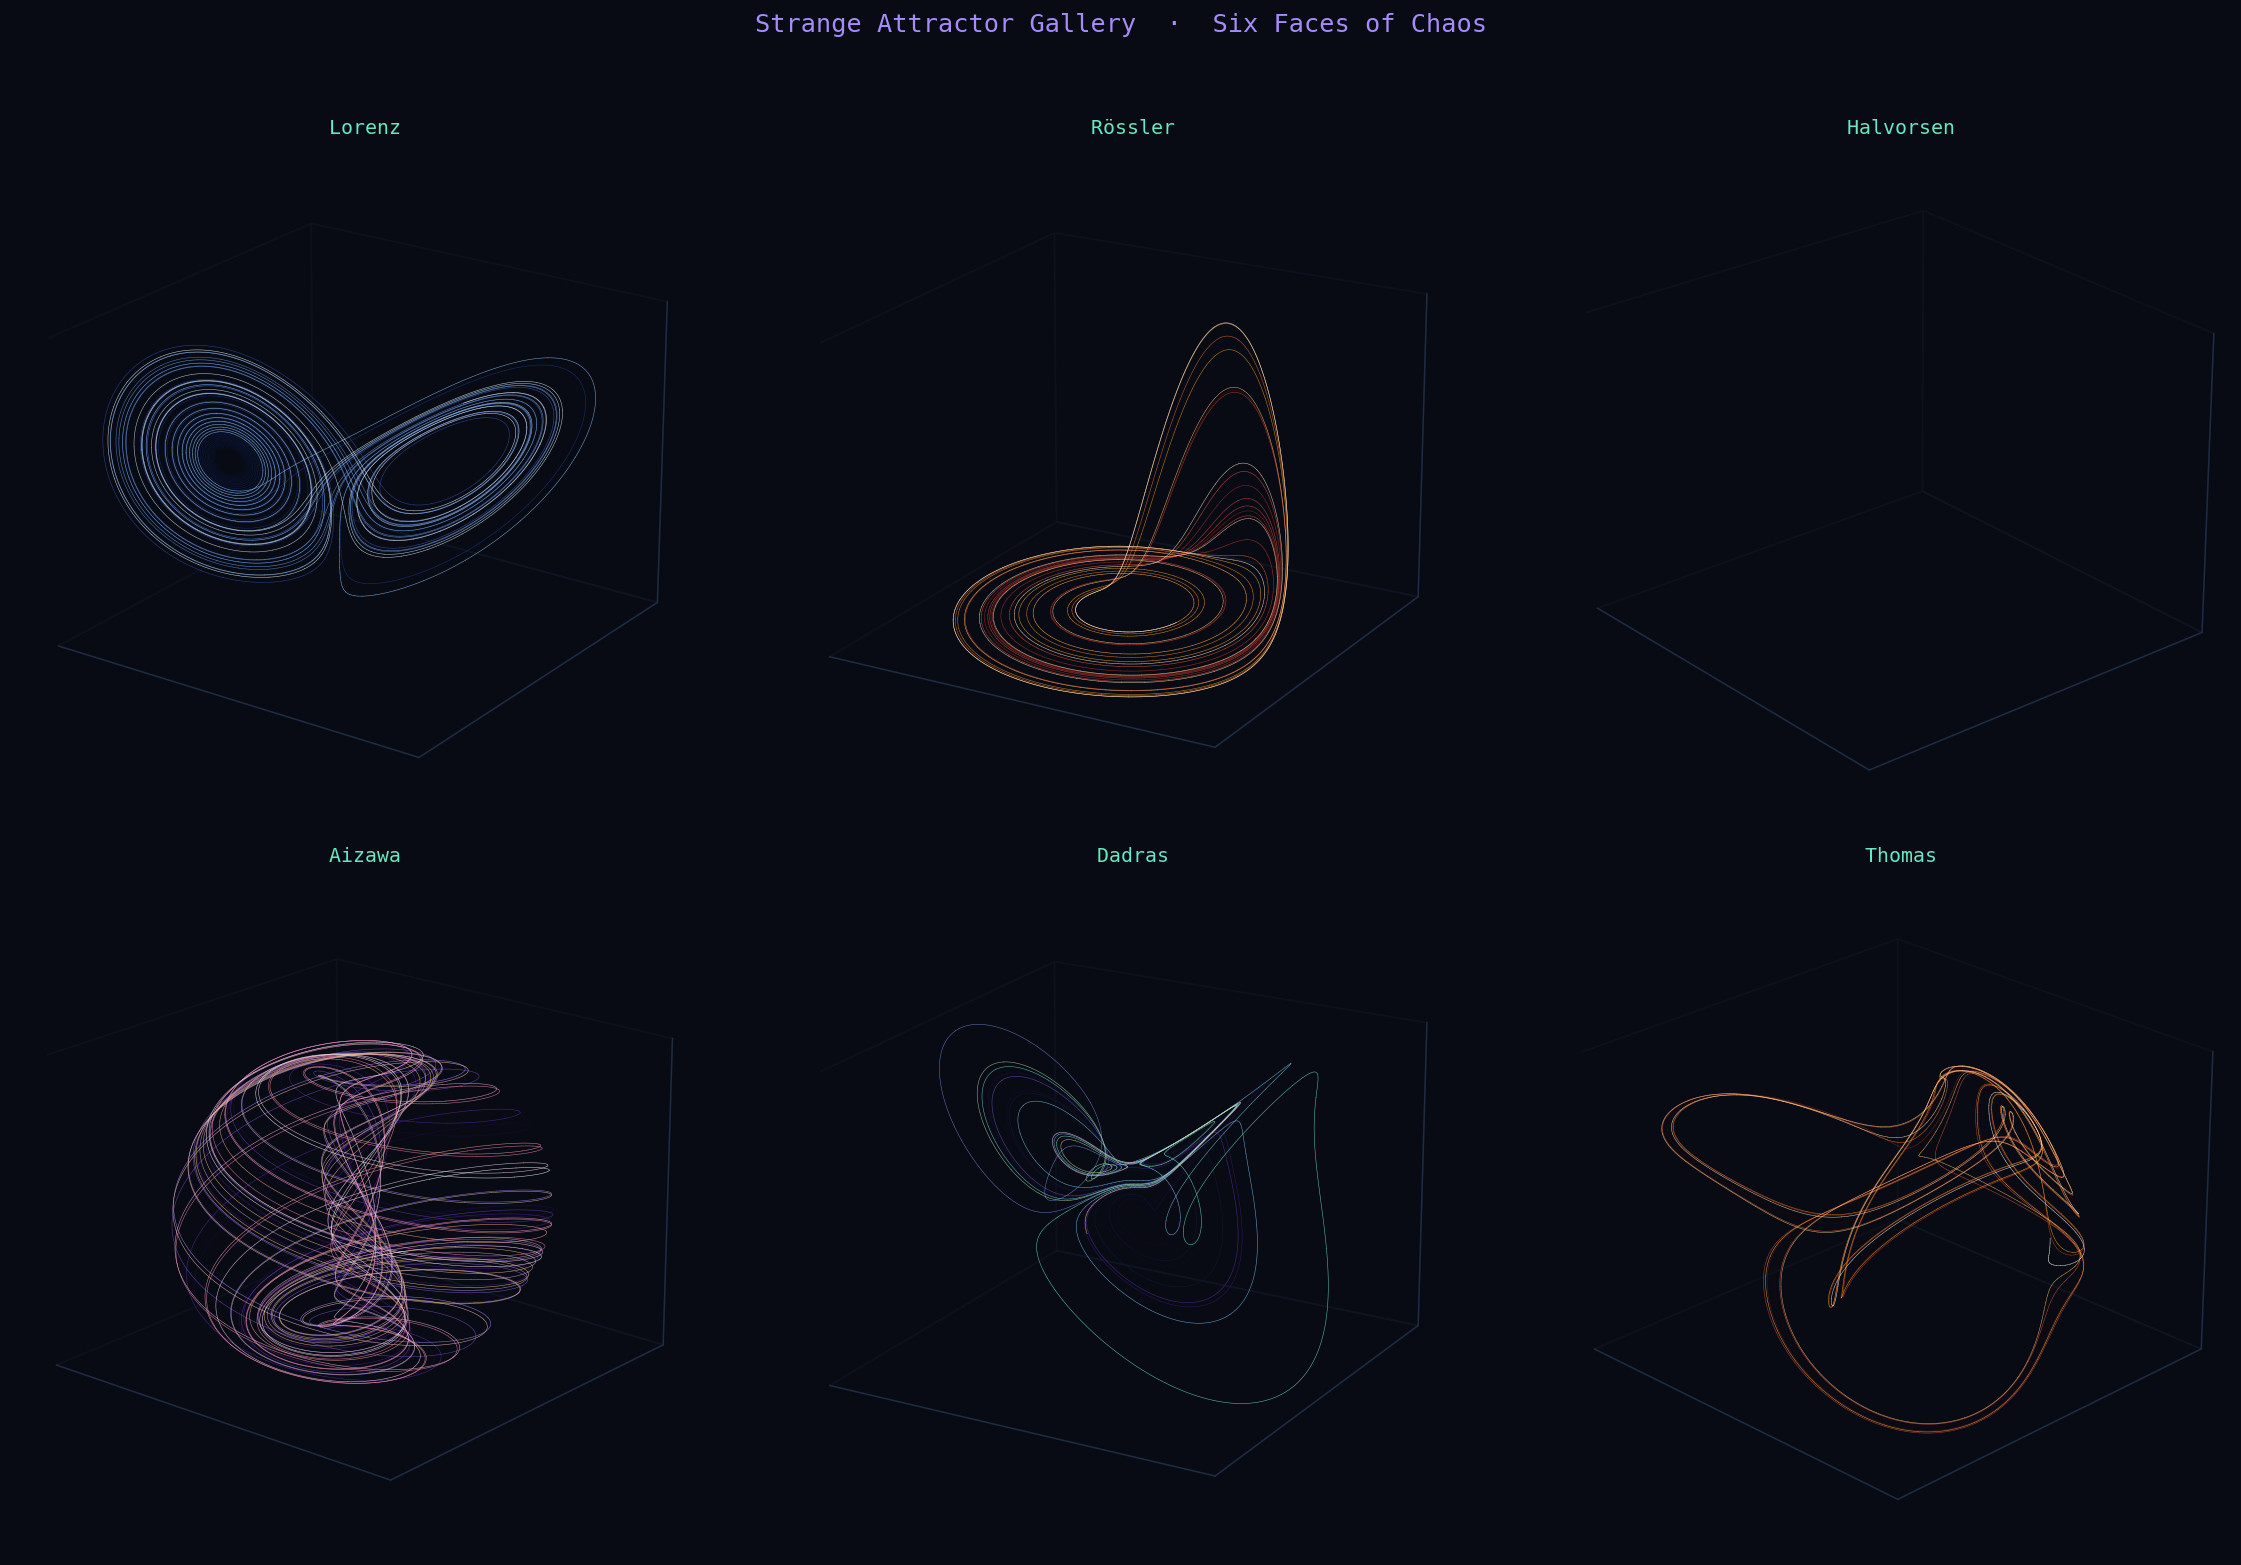

❆  Six systems. Six eternities. All from simple equations.


In [4]:
# ══════════════════════════════════════════════
#  STRANGE ATTRACTOR GALLERY — 6 Systems
# ══════════════════════════════════════════════

def rossler(t, s, a=0.2, b=0.2, c=5.7):
    x,y,z = s
    return [-y-z, x+a*y, b+z*(x-c)]

def halvorsen(t, s, a=1.4):
    x,y,z = s
    return [-a*x - 4*y - 4*z - y**2,
            -a*y - 4*z - 4*x - z**2,
            -a*z - 4*x - 4*y - x**2]

def aizawa(t, s, a=0.95,b=0.7,c=0.6,d=3.5,e=0.25,f=0.1):
    x,y,z = s
    return [(z-b)*x - d*y, d*x + (z-b)*y,
            c + a*z - z**3/3 - (x**2+y**2)*(1+e*z) + f*z*x**3]

def dadras(t, s, a=3,b=2.7,c=1.7,d=2,e=9):
    x,y,z = s
    return [y - a*x + b*y*z, c*y - x*z + z, d*x*y - e*z]

def thomas(t, s, b=0.208186):
    x,y,z = s
    return [np.sin(y)-b*x, np.sin(z)-b*y, np.sin(x)-b*z]

systems = [
    (lorenz,   [0.1,0.,0.],  (0,60),  60_000, CMAPS['lorenz'], 'Lorenz',    (22,-55)),
    (rossler,  [1.,1.,1.],   (0,200), 80_000, CMAPS['fire'],   'R\u00f6ssler',   (20,-60)),
    (halvorsen,[0.,5.,10.],  (0,200), 80_000, CMAPS['chaos'],  'Halvorsen', (25,-40)),
    (aizawa,   [0.1,0.,0.],  (0,250), 80_000, CMAPS['mandel'], 'Aizawa',    (20,-50)),
    (dadras,   [1.,-1.,0.],  (0,100), 60_000, CMAPS['chaos'],  'Dadras',    (20,-60)),
    (thomas,   [0.1,0.,0.],  (0,500),100_000, CMAPS['fire'],   'Thomas',    (25,-45)),
]

fig = plt.figure(figsize=(18, 12))
fig.patch.set_facecolor(PALETTE['bg'])
norm_g = Normalize(0, 1)

for idx, (sys_fn, ic, t_sp, n_pts, cmap, name, view) in enumerate(systems):
    t_ev = np.linspace(*t_sp, n_pts)
    sol = solve_ivp(sys_fn, t_sp, ic, t_eval=t_ev, method='DOP853', rtol=1e-8, atol=1e-10)
    xs, ys, zs = sol.y
    ax = fig.add_subplot(2, 3, idx+1, projection='3d')
    ax.set_facecolor(PALETTE['bg'])
    n_seg = 1500
    seg_len = len(xs)//n_seg
    for i in range(n_seg):
        s,e = i*seg_len,(i+1)*seg_len
        ax.plot(xs[s:e+1],ys[s:e+1],zs[s:e+1],
                color=cmap(norm_g(i/n_seg)), linewidth=0.3, alpha=0.8)
    ax.xaxis.pane.fill=False; ax.yaxis.pane.fill=False; ax.zaxis.pane.fill=False
    ax.xaxis.pane.set_edgecolor('#111827')
    ax.yaxis.pane.set_edgecolor('#111827')
    ax.zaxis.pane.set_edgecolor('#111827')
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    ax.view_init(elev=view[0], azim=view[1])
    ax.set_title(f'  {name}', fontsize=11, color=PALETTE['cyan'], fontfamily='monospace', pad=6)
    ax.grid(False)

fig.suptitle('Strange Attractor Gallery  \u00b7  Six Faces of Chaos',
             fontsize=14, color=PALETTE['purple'], fontfamily='monospace', y=1.01)
plt.tight_layout(pad=2.0)
plt.show()
print("\u2746  Six systems. Six eternities. All from simple equations.")

---

<div style="background: linear-gradient(90deg, #0d2a20, #0a0e1a); padding: 20px 28px; border-radius: 10px; border-left: 4px solid #67e8c0; margin: 20px 0;">
<p style="color: #1a5a40; font-family: monospace; font-size: 0.8em; letter-spacing: 3px; margin: 0 0 4px 0;">§ 03 · THE ROAD TO CHAOS</p>
<h2 style="color: #67e8c0; margin: 0; font-size: 1.8em;">📊 The Bifurcation Diagram</h2>
</div>

Consider the humble **logistic map** — originally a model for animal population dynamics:

$$x_{n+1} = r \cdot x_n \cdot (1 - x_n)$$

- For **r < 3**: population stabilizes to one value
- For **r ≈ 3.45**: oscillates between **2** values
- For **r ≈ 3.54**: oscillates between **4** values
- For **r ≈ 3.57**: **chaos** — infinite, never-repeating values

The period keeps doubling — **1 → 2 → 4 → 8 → 16 → ∞** — until chaos erupts.

> 🔢 **FEIGENBAUM'S CONSTANT**
>
> The ratio between successive bifurcation intervals always converges to **δ ≈ 4.669201...**
> This constant appears in **every** smooth one-dimensional chaotic map — universally.
> It is as fundamental to chaos as **π** is to circles or **e** is to growth.

⟳  Computing bifurcation diagram (4,000 r-values x 400 iterations)...
✓  1,600,000 points computed.


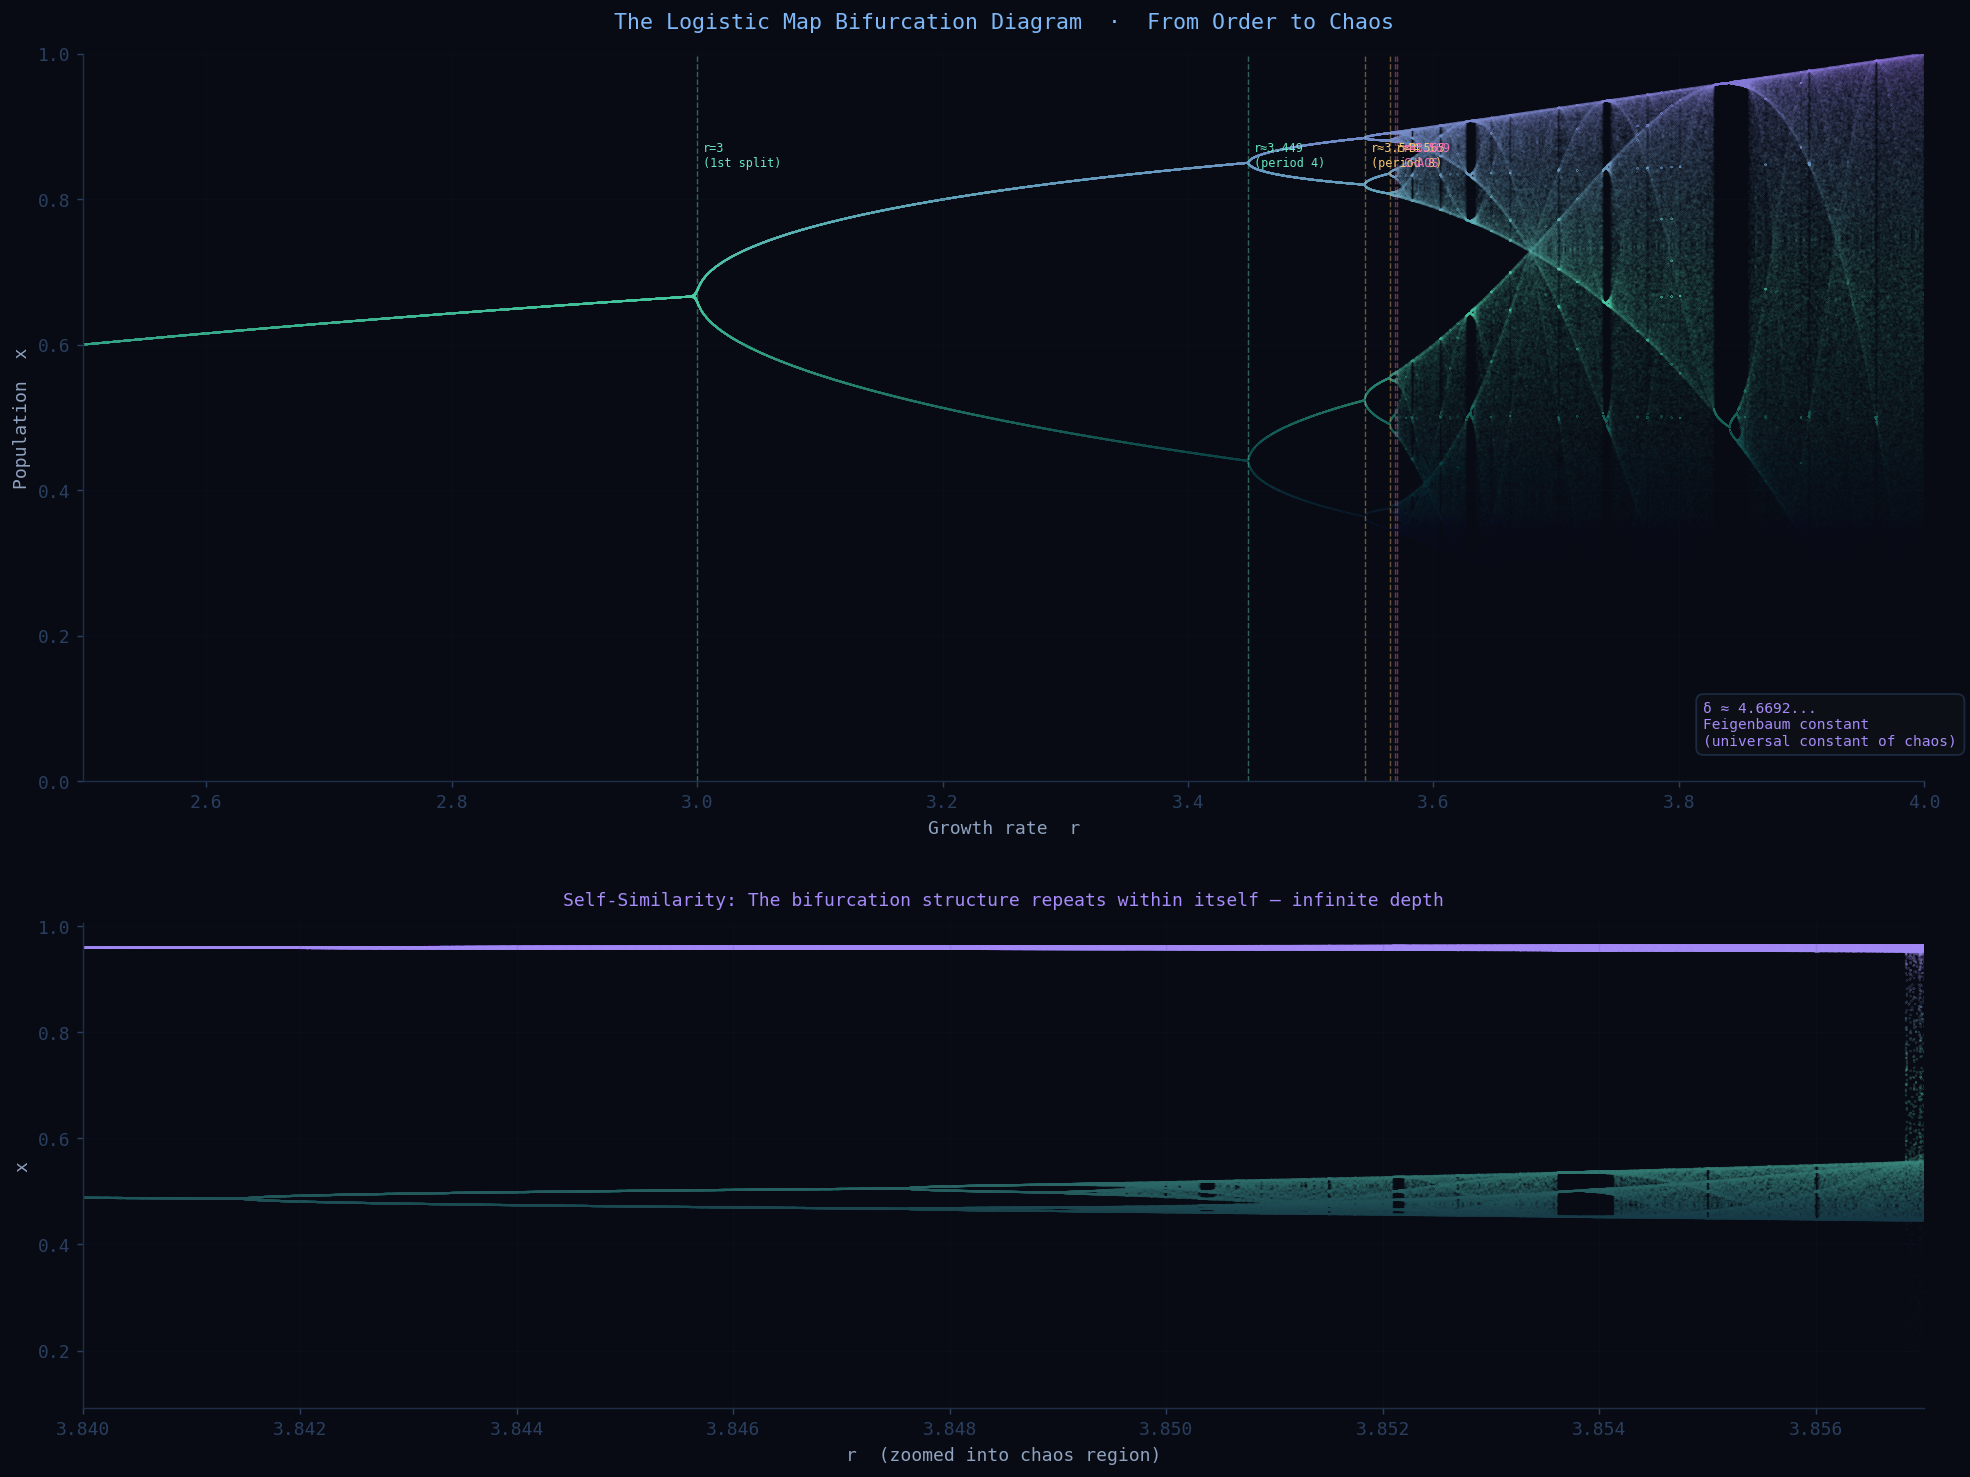

❆  The Feigenbaum constant δ ≈ 4.6692016... is universal across ALL chaotic maps.


In [5]:
# ══════════════════════════════════════════════
#  BIFURCATION DIAGRAM — Pixel-perfect rendering
# ══════════════════════════════════════════════

def bifurcation_data(r_min=2.5, r_max=4.0, r_res=4000, iterations=1200, skip=800):
    r_vals = np.linspace(r_min, r_max, r_res)
    x = 0.5 * np.ones(r_res)
    r_points, x_points = [], []
    for i in range(iterations):
        x = r_vals * x * (1 - x)
        if i >= skip:
            r_points.extend(r_vals)
            x_points.extend(x)
    return np.array(r_points), np.array(x_points)

print("\u27f3  Computing bifurcation diagram (4,000 r-values x 400 iterations)...")
r_pts, x_pts = bifurcation_data(r_res=4000, iterations=1200, skip=800)
print(f"\u2713  {len(r_pts):,} points computed.")

fig, (ax_main, ax_zoom) = plt.subplots(2, 1, figsize=(16, 12),
                                        gridspec_kw={'height_ratios': [3, 2]})
fig.patch.set_facecolor(PALETTE['bg'])

ax_main.set_facecolor(PALETTE['bg'])
ax_main.scatter(r_pts, x_pts, s=0.003, alpha=0.25,
                c=x_pts, cmap=CMAPS['bifur'], rasterized=True)
ax_main.set_xlim(2.5, 4.0); ax_main.set_ylim(0, 1)
ax_main.set_xlabel('Growth rate  r', fontsize=10, color=PALETTE['text'])
ax_main.set_ylabel('Population  x', fontsize=10, color=PALETTE['text'])
ax_main.set_title('The Logistic Map Bifurcation Diagram  \u00b7  From Order to Chaos',
                   fontsize=12, color=PALETTE['blue'], fontfamily='monospace', pad=14)

bif_points = [3.0, 3.449, 3.544, 3.5644, 3.5688, 3.57]
labels_b = ['r=3\n(1st split)', 'r\u22483.449\n(period 4)', 'r\u22483.544\n(period 8)',
            'r\u22483.565', 'r\u22483.569', 'r\u22483.57\nCHAOS']
colors_b = [PALETTE['cyan'], PALETTE['cyan'], PALETTE['gold'],
            PALETTE['gold'], PALETTE['rose'], PALETTE['rose']]
for rval, lbl, col in zip(bif_points, labels_b, colors_b):
    ax_main.axvline(rval, color=col, alpha=0.4, linewidth=0.8, linestyle='--')
    ax_main.text(rval+0.005, 0.88, lbl, fontsize=6.5, color=col,
                 fontfamily='monospace', va='top', ha='left')

ax_main.text(3.82, 0.05,
             '\u03b4 \u2248 4.6692...\nFeigenbaum constant\n(universal constant of chaos)',
             fontsize=8, color=PALETTE['purple'], fontfamily='monospace',
             bbox=dict(facecolor=PALETTE['surface'], edgecolor=PALETTE['border'],
                       alpha=0.9, boxstyle='round,pad=0.5'))
ax_main.grid(True, alpha=0.1)
for spine in ax_main.spines.values(): spine.set_edgecolor(PALETTE['border'])

r_zoom, x_zoom = bifurcation_data(r_min=3.84, r_max=3.857, r_res=2000, iterations=1500, skip=1200)
ax_zoom.set_facecolor(PALETTE['bg'])
ax_zoom.scatter(r_zoom, x_zoom, s=0.05, alpha=0.4,
                c=x_zoom, cmap=CMAPS['bifur'], rasterized=True)
ax_zoom.set_xlim(3.84, 3.857)
ax_zoom.set_xlabel('r  (zoomed into chaos region)', fontsize=10, color=PALETTE['text'])
ax_zoom.set_ylabel('x', fontsize=10, color=PALETTE['text'])
ax_zoom.set_title('Self-Similarity: The bifurcation structure repeats within itself — infinite depth',
                   fontsize=10, color=PALETTE['purple'], fontfamily='monospace', pad=10)
ax_zoom.grid(True, alpha=0.1)
for spine in ax_zoom.spines.values(): spine.set_edgecolor(PALETTE['border'])

plt.tight_layout(pad=3)
plt.show()
print("\u2746  The Feigenbaum constant \u03b4 \u2248 4.6692016... is universal across ALL chaotic maps.")

---

<div style="background: linear-gradient(90deg, #1a0d35, #0a0e1a); padding: 20px 28px; border-radius: 10px; border-left: 4px solid #a78bfa; margin: 20px 0;">
<p style="color: #4a2a8a; font-family: monospace; font-size: 0.8em; letter-spacing: 3px; margin: 0 0 4px 0;">§ 04 · THE MOST COMPLEX OBJECT IN MATHEMATICS</p>
<h2 style="color: #a78bfa; margin: 0; font-size: 1.8em;">∞ The Mandelbrot Set</h2>
</div>

$$z_{n+1} = z_n^2 + c$$

That's it. **One line.** Applied repeatedly to complex numbers `c`, this map either stays bounded (inside the set) or escapes to infinity. The boundary between these two fates is **infinitely complex** — the same level of detail at every zoom level, forever.

The Mandelbrot set has:
- **Hausdorff dimension = 2** — its boundary has infinite length
- **Area ≈ 1.506484** — finite, yet surrounded by infinite complexity
- **Self-similarity** — zoom anywhere on the boundary and find echoes of the whole

> ∞ **INFINITE COMPLEXITY**
>
> You could zoom into the Mandelbrot set for a **million years** and still find new structures —
> spirals containing spirals, each surrounded by miniature copies of the entire set.
> This emerges from a single rule applied over and over.

⟳  Rendering: Full Mandelbrot Set... ✓
⟳  Rendering: Zoom: Seahorse Valley... ✓
⟳  Rendering: Zoom Level 2: Infinite Spirals... ✓


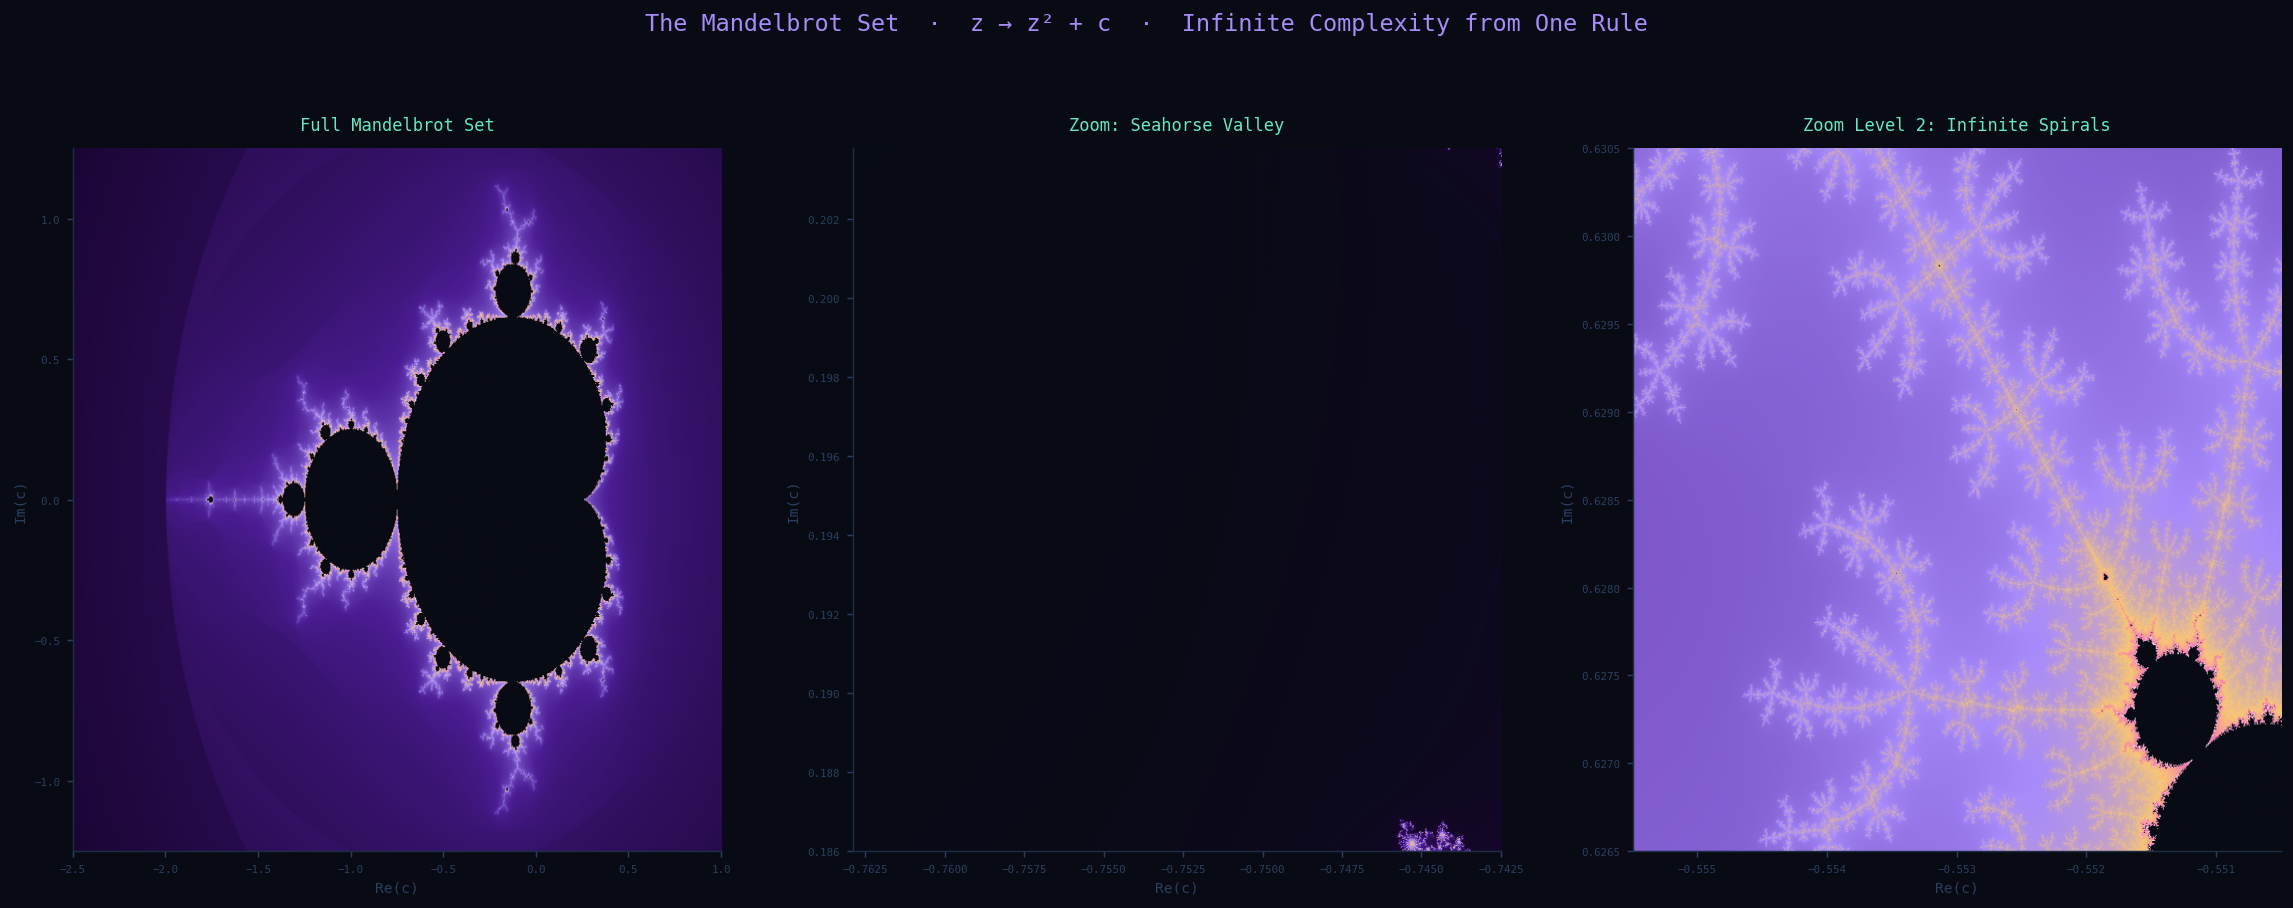

❆  Three zooms. Three eternities. Same boundary.


In [6]:
# ══════════════════════════════════════════════
#  MANDELBROT SET — Smooth iteration coloring
# ══════════════════════════════════════════════

def mandelbrot(c, max_iter=256):
    z = np.zeros_like(c, dtype=complex)
    iters = np.zeros(c.shape, dtype=float)
    mask = np.ones(c.shape, dtype=bool)
    for i in range(max_iter):
        z[mask] = z[mask]**2 + c[mask]
        escaped = mask & (np.abs(z) > 2.0)
        if np.any(escaped):
            iters[escaped] = i + 1 - np.log2(np.log2(np.abs(z[escaped])))
        mask &= ~escaped
    return iters

def render_region(x_min, x_max, y_min, y_max, width=1200, height=900, max_iter=512):
    x = np.linspace(x_min, x_max, width)
    y = np.linspace(y_min, y_max, height)
    C = x[np.newaxis, :] + 1j * y[:, np.newaxis]
    return mandelbrot(C, max_iter)

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
fig.patch.set_facecolor(PALETTE['bg'])

regions = [
    (-2.5, 1.0, -1.25, 1.25, 512, 'Full Mandelbrot Set'),
    (-0.7629, -0.7425, 0.186, 0.2038, 768, 'Zoom: Seahorse Valley'),
    (-0.5555, -0.5505, 0.6265, 0.6305, 1024, 'Zoom Level 2: Infinite Spirals'),
]

for ax, (xmin, xmax, ymin, ymax, mi, title) in zip(axes, regions):
    print(f"\u27f3  Rendering: {title}...", end=" ", flush=True)
    img = render_region(xmin, xmax, ymin, ymax, 900, 700, mi)
    display_img = np.sqrt(np.sqrt(img))
    ax.imshow(display_img, extent=[xmin, xmax, ymin, ymax],
              cmap=CMAPS['mandel'], origin='lower', aspect='auto', interpolation='bilinear')
    ax.set_title(title, fontsize=9.5, color=PALETTE['cyan'], fontfamily='monospace', pad=10)
    ax.set_xlabel('Re(c)', fontsize=8, color=PALETTE['dim'])
    ax.set_ylabel('Im(c)', fontsize=8, color=PALETTE['dim'])
    ax.tick_params(colors=PALETTE['dim'], labelsize=6)
    for spine in ax.spines.values(): spine.set_edgecolor(PALETTE['border'])
    print("\u2713")

fig.suptitle('The Mandelbrot Set  \u00b7  z \u2192 z\u00b2 + c  \u00b7  Infinite Complexity from One Rule',
             fontsize=13, color=PALETTE['purple'], fontfamily='monospace', y=1.01)
plt.tight_layout(pad=2)
plt.show()
print("\u2746  Three zooms. Three eternities. Same boundary.")

---

## Continue

Part 1 ends here. [Part 2](the-art-of-chaos-part2.ipynb) covers the Julia set gallery, Lyapunov exponents, the animated Lorenz attractor, and Poincare sections.
